**عيار** | **تحليل** **سوق** **الذهب**  ⭐  
**EYAR**: **Gold** **Market** **Analysis**
--------------------------------------------------------------------------------
## 1. **Dataset**

Title: Daily Gold and Oil Prices (2015 to Oct 2026)    

Source: Gold futures (GC=F) from Yahoo Finance, and WTI oil prices (DCOILWTICO) from FRED.  

Description: Daily prices of gold and oil, the data was merged by date and saved as a clean CSV. The data is frozen at 26 Oct 2026.

Why I chose it:  
I am interested in gold, and many people in Saudi Arabia buy it for saving and jewelry, and I have always been **curious** about why gold prices rise and fall?   
  When I asked my **grandmother**, who has years of experience with gold, she explained that oil prices and global events can influence its price. This inspired me to explore these relationships using real data.

--------------------------------------------------------------------------------

## 2. **Problem** **Definition**

What is the dataset about?

The daily price of gold and oil over almost 12 years.

Questions I will explore:

1. Does gold rise in the long run?  
2. Which years were the strongest and weakest for gold?  
3. Do gold and oil move together?  
4. Does gold rise during major global events?  
5. How risky is gold?  
6. Is gold a good long-term investment  


Expected insights:   
I expected gold and oil to have a strong inverse relationship, meaning gold prices would fall when oil prices rise, and rise when oil prices fall.

## **3.** **Setup**




In [117]:
!pip -q install yfinance

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_style("whitegrid")

## **4.** **Data** **Collection**

### **Note**:
###The data was downloaded on October 26, 2026. The end date is fixed in the code to keep the analysis period consistent.

In [118]:
gold = yf.download("GC=F", start="2015-01-01", end="2026-10-27", progress=False)
gold.columns = gold.columns.get_level_values(0)
gold = gold.reset_index()
print(gold.shape)
gold.head()

(2971, 6)


/tmp/ipykernel_3544/3684322320.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  gold = yf.download("GC=F", start="2015-01-01", end="2026-10-27", progress=False)


Price,Date,Close,High,Low,Open,Volume
0,2015-01-02,1186.000000,1194.500000,1169.500000,1184.000000,138
1,2015-01-05,1203.900024,1206.900024,1180.099976,1180.300049,470
2,2015-01-06,1219.300049,1220.000000,1203.500000,1203.500000,97
3,2015-01-07,1210.599976,1219.199951,1210.599976,1219.199951,29
4,2015-01-08,1208.400024,1215.699951,1206.300049,1207.000000,92


In [119]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILWTICO"
oil = pd.read_csv(url)
print(oil.shape)
oil.head()

(10649, 2)


,observation_date,DCOILWTICO
0,1986-01-02,25.56
1,1986-01-03,26.00
2,1986-01-06,26.53
3,1986-01-07,25.85
4,1986-01-08,25.87


In [120]:
gold.to_csv("gold.csv", index=False)
oil.to_csv("oil.csv", index=False)

# files.download("gold.csv")
# files.download("oil.csv")

## **5.** **Data** **Exploration**

In [121]:
gold.shape

(2971, 6)

In [122]:
oil.shape

(10649, 2)

In [123]:
gold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2971 entries, 0 to 2970
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    2971 non-null   datetime64[ns]
 1   Close   2971 non-null   float64       
 2   High    2971 non-null   float64       
 3   Low     2971 non-null   float64       
 4   Open    2971 non-null   float64       
 5   Volume  2971 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 139.4 KB


In [124]:
oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10649 entries, 0 to 10648
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  10649 non-null  object 
 1   DCOILWTICO        9532 non-null   float64
dtypes: float64(1), object(1)
memory usage: 166.5+ KB


In [125]:
print(gold.isnull().sum())
print()
print(oil.isnull().sum())

Price
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

observation_date       0
DCOILWTICO          1117
dtype: int64


In [126]:
print(gold.duplicated().sum())
print(oil.duplicated().sum())

0
0


In [127]:
print(gold.describe())
print()
print(oil.describe())

Price                           Date        Close         High          Low  \
count                           2971  2971.000000  2971.000000  2971.000000   
mean   2020-11-29 09:55:11.612252160  1966.458802  1981.401952  1950.862841   
min              2015-01-02 00:00:00  1050.800049  1062.000000  1046.199951   
25%              2017-12-14 12:00:00  1278.549988  1283.700012  1274.900024   
50%              2020-11-30 00:00:00  1751.699951  1762.099976  1739.500000   
75%              2023-11-11 12:00:00  2019.149963  2036.599976  2004.299988   
max              2026-10-26 00:00:00  5318.399902  5586.200195  5272.899902   
std                              NaN   956.730067   971.174392   941.292637   

Price         Open         Volume  
count  2971.000000    2971.000000  
mean   1966.319522  109158.895658  
min    1053.699951       0.000000  
25%    1279.400024     148.000000  
50%    1752.000000  122702.000000  
75%    2019.549988  192724.500000  
max    5415.700195  570055.000000  


### **Gold Notes**

- No missing values or duplicate rows.
- `Date` is already in datetime format.
- `Volume` has zero values and changes a lot over time. I will remove it because my analysis focuses on prices.
- I will remove the extra label `Price` above the columns.

### **Oil Notes**

- The data starts in 1986, but I only need data from 2015 to match the gold data.
- There are 1,117 missing values in the full dataset. I will check again after keeping only data from 2015.
- The lowest price is -36.98 in April 2020. This happened during COVID-19, so I will keep it.
- I will rename `observation_date` and `DCOILWTICO` to make them easier to understand.

### **Cleaning Plan**

1. Convert the oil date column to datetime.
2. Keep oil data from 2015 onward.
3. Rename the oil columns to `Date` and `Oil_Price`.
4. Check missing values again and decide how to handle them.
5. Merge gold and oil data using `Date`.

## **6.** **Data** **Cleaning**

In [128]:
# Convert the date column from text to real dates
oil["observation_date"] = pd.to_datetime(oil["observation_date"])

In [129]:
# Keep only data from 2015 onward (to match the gold data)
oil = oil[oil["observation_date"] >= "2015-01-01"].copy()

In [130]:
# Rename the columns to clearer names
oil = oil.rename(columns={"observation_date": "Date", "DCOILWTICO": "Oil_Price"})

In [131]:
print(oil.shape)
print()
print(oil.isnull().sum())

(3084, 2)

Date           0
Oil_Price    133
dtype: int64


In [132]:
# Remove the Volume column (we focus on prices)
gold = gold.drop(columns=["Volume"])

In [133]:
# Remove the extra label "Price" above the column names
gold.columns.name = None
gold.head()

,Date,Close,High,Low,Open
0,2015-01-02,1186.000000,1194.500000,1169.500000,1184.000000
1,2015-01-05,1203.900024,1206.900024,1180.099976,1180.300049
2,2015-01-06,1219.300049,1220.000000,1203.500000,1203.500000
3,2015-01-07,1210.599976,1219.199951,1210.599976,1219.199951
4,2015-01-08,1208.400024,1215.699951,1206.300049,1207.000000


In [134]:
# Show the first 10 rows where the oil price is missing
oil[oil["Oil_Price"].isnull()].head(10)

,Date,Oil_Price
7565,2015-01-01,NaN
7570,2015-01-08,NaN
7577,2015-01-19,NaN
7580,2015-01-22,NaN
7582,2015-01-26,NaN
7583,2015-01-27,NaN
7584,2015-01-28,NaN
7585,2015-01-29,NaN
7587,2015-02-02,NaN
7589,2015-02-04,NaN


###- Oil has 133 missing prices after 2015. Only a few are US holidays (Jan 1 and Jan 19, 2015).

###- Most are normal working days where gold has data, so these are gaps in the oil data source.

In [135]:
# Merge gold and oil on Date (keep all gold trading days)
df = gold.merge(oil, on="Date", how="left")
print(df.shape)
print()
print(df.isnull().sum())

(2971, 6)

Date          0
Close         0
High          0
Low           0
Open          0
Oil_Price    25
dtype: int64


In [136]:
df.head()

,Date,Close,High,Low,Open,Oil_Price
0,2015-01-02,1186.000000,1194.500000,1169.500000,1184.000000,52.72
1,2015-01-05,1203.900024,1206.900024,1180.099976,1180.300049,50.05
2,2015-01-06,1219.300049,1220.000000,1203.500000,1203.500000,47.98
3,2015-01-07,1210.599976,1219.199951,1210.599976,1219.199951,48.69
4,2015-01-08,1208.400024,1215.699951,1206.300049,1207.000000,NaN


In [137]:
# Fill missing oil prices with the last known price (forward fill)
df["Oil_Price"] = df["Oil_Price"].ffill()
print(df.isnull().sum())

Date         0
Close        0
High         0
Low          0
Open         0
Oil_Price    0
dtype: int64


In [138]:
# Check the data types and duplicates of the merged table
df.info()
print()
print(f"There is {df.duplicated().sum()} duplicates")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2971 entries, 0 to 2970
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       2971 non-null   datetime64[ns]
 1   Close      2971 non-null   float64       
 2   High       2971 non-null   float64       
 3   Low        2971 non-null   float64       
 4   Open       2971 non-null   float64       
 5   Oil_Price  2971 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 139.4 KB

There is 0 duplicates


In [139]:
df

,Date,Close,High,Low,Open,Oil_Price
0,2015-01-02,1186.000000,1194.500000,1169.500000,1184.000000,52.72
1,2015-01-05,1203.900024,1206.900024,1180.099976,1180.300049,50.05
2,2015-01-06,1219.300049,1220.000000,1203.500000,1203.500000,47.98
3,2015-01-07,1210.599976,1219.199951,1210.599976,1219.199951,48.69
4,2015-01-08,1208.400024,1215.699951,1206.300049,1207.000000,48.69
...,...,...,...,...,...,...
2966,2026-10-20,4142.600098,4174.899902,4130.100098,4162.399902,107.89
2967,2026-10-21,4150.000000,4160.600098,4122.299805,4143.399902,103.95
2968,2026-10-22,4060.399902,4164.299805,4036.800049,4159.000000,104.27
2969,2026-10-23,4007.899902,4050.199951,3989.100098,4042.199951,109.72


### **7. Feature Engineering**

In [140]:
# Calculate the daily return (% change from the previous day)
df["Gold_Return"] = df["Close"].pct_change() * 100
df["Oil_Return"] = df["Oil_Price"].pct_change() * 100

In [141]:
# Show the first rows to check the new columns
df[["Date", "Close", "Gold_Return", "Oil_Price", "Oil_Return"]].head()

,Date,Close,Gold_Return,Oil_Price,Oil_Return
0,2015-01-02,1186.000000,NaN,52.72,NaN
1,2015-01-05,1203.900024,1.509277,50.05,-5.064492
2,2015-01-06,1219.300049,1.279178,47.98,-4.135864
3,2015-01-07,1210.599976,-0.713530,48.69,1.479783
4,2015-01-08,1208.400024,-0.181724,48.69,0.000000


In [142]:
# Summary statistics of the daily returns
print(df[["Gold_Return", "Oil_Return"]].describe())

       Gold_Return   Oil_Return
count  2970.000000  2970.000000
mean      0.046861    -0.046399
std       1.056629     6.794965
min     -10.779554  -301.966139
25%      -0.445274    -1.322368
50%       0.046984     0.101459
75%       0.587259     1.458758
max       6.069722    53.086420


In [143]:
# Show the days where the oil return is below -100% (not possible normally)
df[df["Oil_Return"] < -100][["Date", "Oil_Price", "Oil_Return"]]

,Date,Oil_Price,Oil_Return
1329,2020-04-20,-36.98,-301.966139
1330,2020-04-21,8.91,-124.094105


###- Oil prices turned negative in April 2020, so the percentage change is not meaningful on those days (it gave -302%, and the wrong sign the next day). I kept the prices but set the oil return for these days to NaN.

In [144]:
# Oil % change is not meaningful around negative prices, so set these days to NaN
df.loc[df["Oil_Return"] < -100, "Oil_Return"] = np.nan

In [145]:
# Summary statistics of the daily returns
print(df[["Gold_Return", "Oil_Return"]].describe())

       Gold_Return   Oil_Return
count  2970.000000  2968.000000
mean      0.046861     0.097121
std       1.056629     3.205092
min     -10.779554   -24.526009
25%      -0.445274    -1.321226
50%       0.046984     0.102809
75%       0.587259     1.461307
max       6.069722    53.086420


In [146]:
# Extract the year and the month from the Date column
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

In [147]:
df.head()

,Date,Close,High,Low,Open,Oil_Price,Gold_Return,Oil_Return,Year,Month
0,2015-01-02,1186.000000,1194.500000,1169.500000,1184.000000,52.72,NaN,NaN,2015,1
1,2015-01-05,1203.900024,1206.900024,1180.099976,1180.300049,50.05,1.509277,-5.064492,2015,1
2,2015-01-06,1219.300049,1220.000000,1203.500000,1203.500000,47.98,1.279178,-4.135864,2015,1
3,2015-01-07,1210.599976,1219.199951,1210.599976,1219.199951,48.69,-0.713530,1.479783,2015,1
4,2015-01-08,1208.400024,1215.699951,1206.300049,1207.000000,48.69,-0.181724,0.000000,2015,1


In [148]:
# Save the final clean table as a CSV file and download it
df.to_csv("gold_oil_clean.csv", index=False)
# files.download("gold_oil_clean.csv")

### **Summary of New Columns and Final Dataset**


- **Gold_Return** and **Oil_Return** measure the daily percentage change in prices. I used these to compare daily movements, since rising prices alone do not mean gold and oil move together.
- The first return is NaN because there is no previous day for comparison.
- **Oil_Return** was set to NaN for April 20 and 21, 2020, because the negative oil price on April 20 makes both days’ percentage changes difficult to interpret.  
- I added **Year** and **Month** from `Date` to compare different years.

### **Final** **Dataset**


- 2,971 rows and 10 columns, covering gold trading days from January 2015 to October 2026.
- No duplicate rows. The only missing values are 3 in **Oil_Return** and 1 in **Gold_Return**, for the reasons explained above.
- Saved as `gold_oil_clean.csv`.

In [149]:
# Load the clean table (parse Date as real dates)
df = pd.read_csv("gold_oil_clean.csv", parse_dates=["Date"])
df.head()

,Date,Close,High,Low,Open,Oil_Price,Gold_Return,Oil_Return,Year,Month
0,2015-01-02,1186.000000,1194.500000,1169.500000,1184.000000,52.72,NaN,NaN,2015,1
1,2015-01-05,1203.900024,1206.900024,1180.099976,1180.300049,50.05,1.509277,-5.064492,2015,1
2,2015-01-06,1219.300049,1220.000000,1203.500000,1203.500000,47.98,1.279178,-4.135864,2015,1
3,2015-01-07,1210.599976,1219.199951,1210.599976,1219.199951,48.69,-0.713530,1.479783,2015,1
4,2015-01-08,1208.400024,1215.699951,1206.300049,1207.000000,48.69,-0.181724,0.000000,2015,1


## **8.** **Analysis** **&** **Insights**

### **Q1. Does gold rise in the long run?**

In [150]:
# First and last gold price in the data
first_price = df["Close"].iloc[0]
last_price = df["Close"].iloc[-1]
growth = (last_price - first_price) / first_price * 100

print("First price:", round(first_price, 2))
print("Last price:", round(last_price, 2))
print("Total growth (%):", round(growth, 1))

First price: 1186.0
Last price: 4038.4
Total growth (%): 240.5


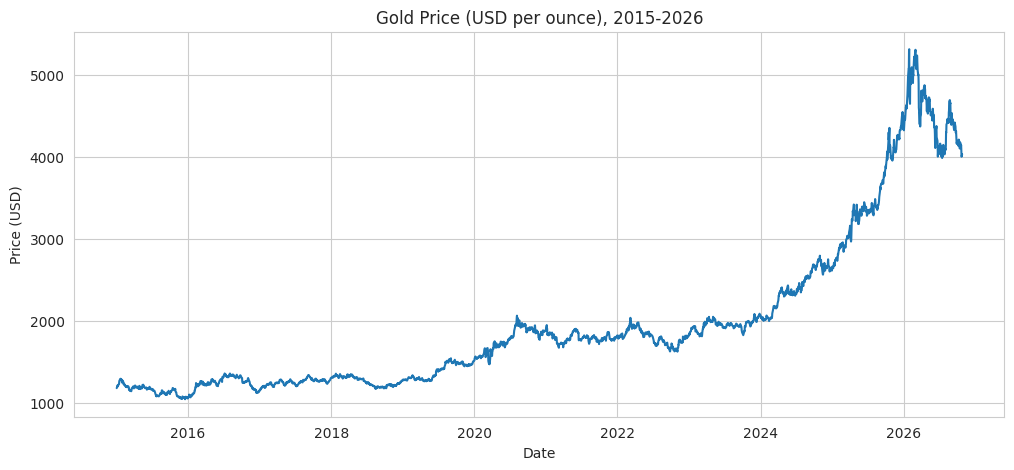

In [151]:
#gold price over time
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.title("Gold Price (USD per ounce), 2015-2026")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.show()

In [152]:
df["Close"].max()

5318.39990234375

In [153]:
# Show the full row of the highest closing price
df.loc[[df["Close"].idxmax()]]

,Date,Close,High,Low,Open,Oil_Price,Gold_Return,Oil_Return,Year,Month
2784,2026-01-29,5318.399902,5586.200195,5097.5,5415.700195,64.77,0.279052,3.219124,2026,1


In [154]:
# Show the full row of the lowest closing price
df.loc[[df["Close"].idxmin()]]

,Date,Close,High,Low,Open,Oil_Price,Gold_Return,Oil_Return,Year,Month
242,2015-12-17,1050.800049,1072.599976,1050.5,1072.599976,34.98,-2.523187,-1.603376,2015,12


In [155]:
# Day name of the highest and lowest closing price
print(df.loc[df["Close"].idxmax(), "Date"].day_name())
print(df.loc[df["Close"].idxmin(), "Date"].day_name())

Thursday
Thursday


### **What the Data Shows:**

- Gold rose from 1,186 (January 2015) to 4,038 (October 2026), a growth of +240%. The price more than tripled.
- The rise was not smooth. Gold stayed roughly flat from 2015 to 2019, and again from mid-2020 to early 2024.
- The strong rise started in 2024 and peaked at a closing price of $5,318 on January 29, 2026. Since then, the price has dropped about 24%.

### **Insight:**     
Gold rose in the long run, but not in a straight line. Most of the gain came in a short period, and it can fall sharply after a peak.

### **Q2. Which years were the strongest and weakest for gold?**


In [156]:
# Yearly return: change from the first to the last price of each year
grp = df.groupby("Year")["Close"]
yearly_return = (grp.last() - grp.first()) / grp.first() * 100
print(yearly_return.round(1))

Year
2015   -10.6
2016     7.0
2017    12.6
2018    -2.7
2019    18.6
2020    24.3
2021    -6.1
2022     1.4
2023    12.2
2024    27.4
2025    62.6
2026    -6.7
Name: Close, dtype: float64


In [157]:
# Find the best and worst year
print("Best year:", yearly_return.idxmax(), round(yearly_return.max(), 1))
print("Worst year:", yearly_return.idxmin(), round(yearly_return.min(), 1))

Best year: 2025 62.6
Worst year: 2015 -10.6


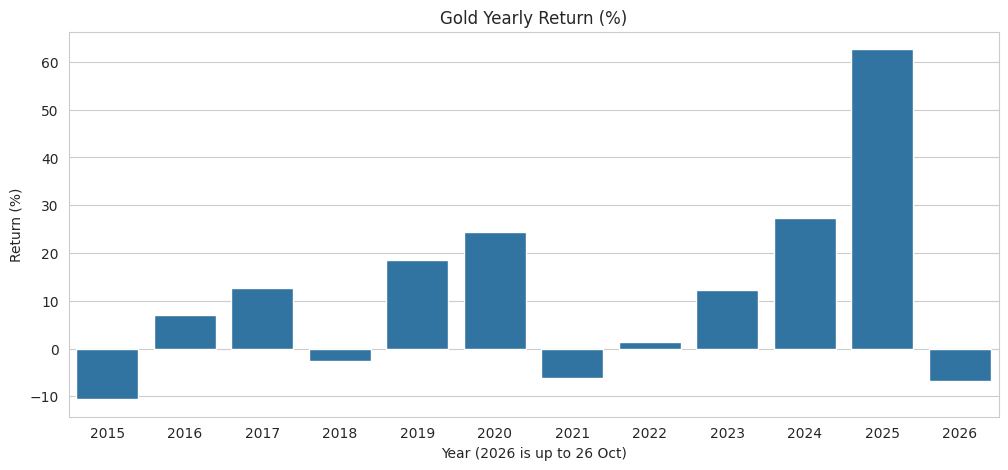

In [158]:
# Plot the yearly returns
plt.figure(figsize=(12, 5))
sns.barplot(x=yearly_return.index, y=yearly_return.values)
plt.title("Gold Yearly Return (%)")
plt.xlabel("Year (2026 is up to 26 Oct)")
plt.ylabel("Return (%)")
plt.show()

### **What the Data Shows:**
- Gold rose in 8 of 12 years and fell in 4 (2015, 2018, 2021 and 2026, where 2026 is a partial year up to October).
- The best year was 2025 (+62.6%), much higher than any other year. The weakest complete year was 2015 (-10.6%).  
- Yearly return is calculated from the first close to the last close inside each year.

### **Insight:**   
Gold does not rise every year, and a large part of its total gain came from one exceptional year (2025).

### **Q3. Do gold and oil move together?**

In [159]:
# Correlation between the PRICES (can be misleading)
print("Prices:", round(df["Close"].corr(df["Oil_Price"]), 2))

# Correlation between the DAILY RETURNS (more reliable)
print("Returns:", round(df["Gold_Return"].corr(df["Oil_Return"]), 2))

Prices: 0.43
Returns: 0.04


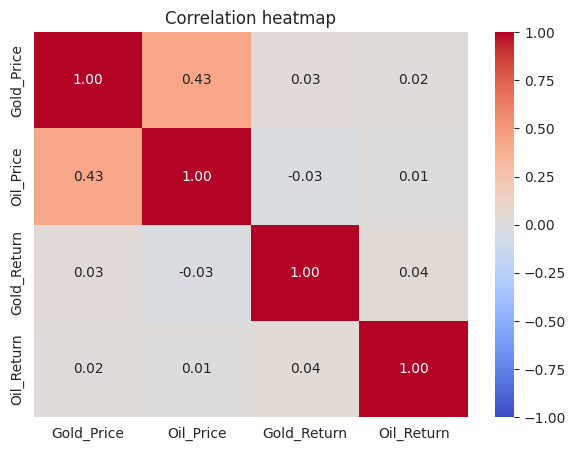

In [160]:
# Choose the columns to compare
cols = ["Close", "Oil_Price", "Gold_Return", "Oil_Return"]

# Copy the columns and give "Close" a clearer name (only here)
small = df[cols].rename(columns={"Close": "Gold_Price"})

# Calculate the correlation between every two columns
corr = small.corr()

# Draw it as a colored table
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

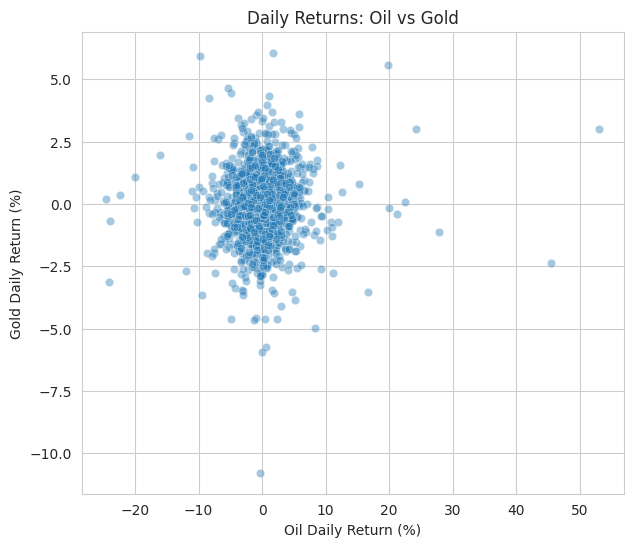

In [161]:
# Scatter plot of daily returns: oil vs gold
plt.figure(figsize=(7, 6))
sns.scatterplot(data=df, x="Oil_Return", y="Gold_Return", alpha=0.4)
plt.title("Daily Returns: Oil vs Gold")
plt.xlabel("Oil Daily Return (%)")
plt.ylabel("Gold Daily Return (%)")
plt.show()

### **What the Data Shows:**

- The correlation between the prices is +0.43 (moderate), but this is misleading, because both prices change over time.  
- The correlation between the daily returns is only +0.04, which is almost zero.   
- The scatter plot shows a round cloud of points around zero, with no clear direction.  
- My initial hypothesis was an inverse relationship, but the data **does not** support it.  
- The heatmap shows the same result in one picture.  

### **Insight:**   
- On a day-to-day basis, oil price movements say almost nothing about gold movements.  

- Limitation: this measures same-day linear relationships only

### **Q4. Does gold rise during major global events?**

In [162]:
# Create a small table of global events
events = pd.DataFrame({
    "Event": ["COVID-19 declared a pandemic", "Russia invades Ukraine", "Gaza war begins"],
    "Date": pd.to_datetime(["2020-03-11", "2022-02-24", "2023-10-07"])
})
events

,Event,Date
0,COVID-19 declared a pandemic,2020-03-11
1,Russia invades Ukraine,2022-02-24
2,Gaza war begins,2023-10-07


In [163]:
# Measure the gold change around each event (in trading days)
results = []

for i in range(len(events)):
    event_date = events.loc[i, "Date"]
    pos = df[df["Date"] >= event_date].index[0]   # first trading day on or after the event
    base_pos = pos - 1                             # last trading day BEFORE the event
    base = df.loc[base_pos, "Close"]

    before_30 = (base - df.loc[base_pos - 30, "Close"]) / df.loc[base_pos - 30, "Close"] * 100
    after_7 = (df.loc[base_pos + 7, "Close"] - base) / base * 100
    after_30 = (df.loc[base_pos + 30, "Close"] - base) / base * 100

    results.append([events.loc[i, "Event"], df.loc[base_pos, "Date"].date(),
                    round(before_30, 1), round(after_7, 1), round(after_30, 1)])

pd.DataFrame(results, columns=["Event", "Last close before event",
                               "Before 30 days (%)", "After 7 days (%)", "After 30 days (%)"])

,Event,Last close before event,Before 30 days (%),After 7 days (%),After 30 days (%)
0,COVID-19 declared a pandemic,2020-03-10,5.2,-10.9,4.2
1,Russia invades Ukraine,2022-02-23,6.2,2.9,0.7
2,Gaza war begins,2023-10-06,-5.2,4.9,7.6


In [164]:
# Typical 30-day change of gold (for comparison)
typical_30 = df["Close"].pct_change(30) * 100
print("Average:", round(typical_30.mean(), 1))
print("Typical range:", round(typical_30.quantile(0.25), 1), "to", round(typical_30.quantile(0.75), 1))

Average: 1.4
Typical range: -2.1 to 4.9


### **What the Data Shows:**

**Method:** For each event, I measured the gold change 30 days before and 7 and 30 days after the event, and compared it with the typical 30-day change (average +1.4%, middle range from -2.1% to +4.9%).

**Findings**
- COVID-19 (March 2020): gold fell 10.9% in the first 7 days, then recovered (+4.2% after 30 days).
- Russia invades Ukraine (Feb 2022): gold rose only +0.7% after 30 days, within the normal range. It had already risen 6.2% in the 30 days before the event.
- Gaza war (Oct 2023): gold rose +7.6% after 30 days, above the normal range.

### **Insight:**
 Gold does not react the same way to every global event. It fell, stayed flat, or rose, and sometimes the move happened before the event. Limitation: only 3 events, and other factors may have affected gold at the same time, so this shows timing, not cause.

### **Q5. How risky is gold?**

### 5.1 Falls from the peak

In [165]:
# Highest price reached so far (running maximum)
df["Running_Max"] = df["Close"].cummax()

# Drawdown: how far the price is below its previous peak (%)
df["Drawdown"] = (df["Close"] - df["Running_Max"]) / df["Running_Max"] * 100

print("Maximum drawdown (%):", round(df["Drawdown"].min(), 1))
print("Date of the maximum drawdown:", df.loc[df["Drawdown"].idxmin(), "Date"].date())

Maximum drawdown (%): -24.9
Date of the maximum drawdown: 2026-07-16


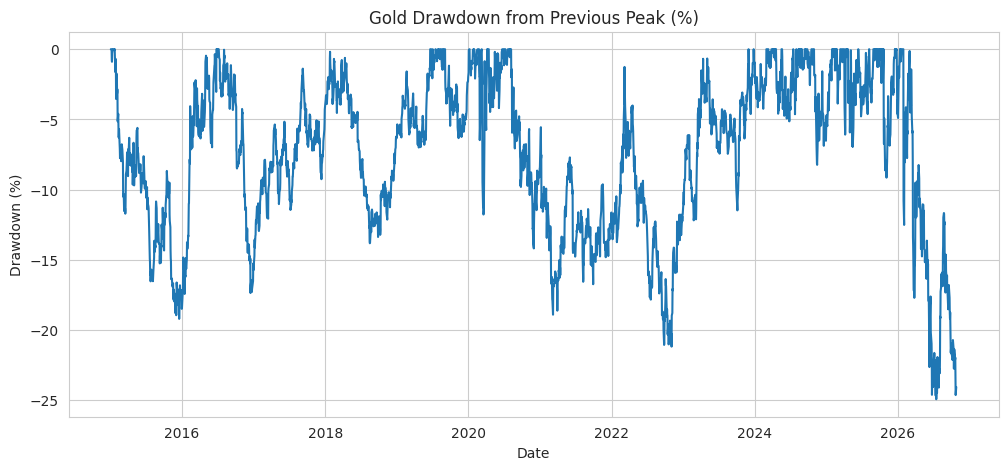

In [166]:
# Plot the drawdown over time
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Drawdown"])
plt.title("Gold Drawdown from Previous Peak (%)")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.show()

### **What the Data Shows:**

- The largest drop from a previous peak was 24.9%, recorded in July 2026.
- Drops of 15–21% from previous peaks happened several times in the dataset.

### **What it means**

- Gold can fall sharply after reaching a high price. In this dataset, buying at a peak could mean seeing the investment lose around 15–25% of its value.

### 5.2 Daily moves

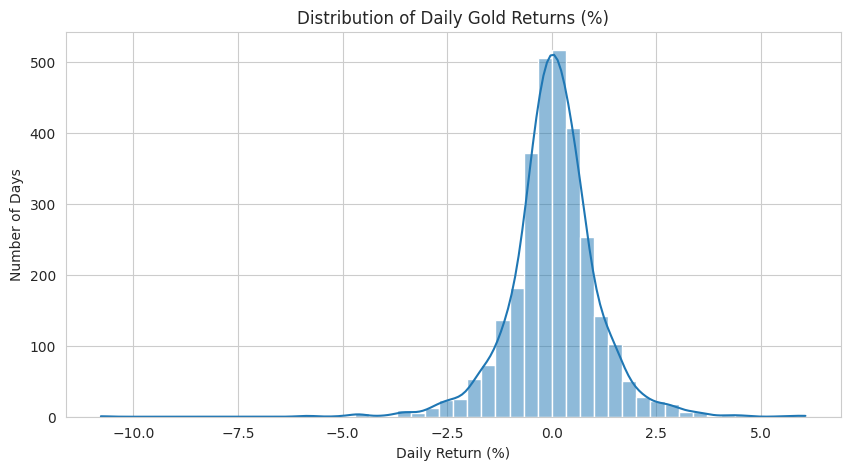

In [167]:
# Distribution of the daily gold returns
plt.figure(figsize=(10, 5))
sns.histplot(df["Gold_Return"].dropna(), bins=50, kde=True)
plt.title("Distribution of Daily Gold Returns (%)")
plt.xlabel("Daily Return (%)")
plt.ylabel("Number of Days")
plt.show()

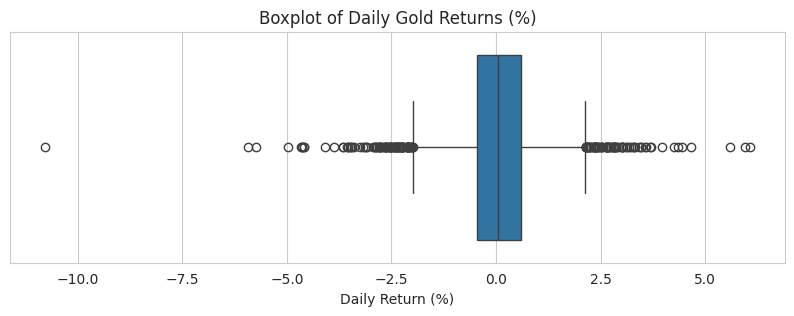

In [168]:
# Boxplot of daily gold returns (the dots are the extreme days)
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["Gold_Return"].dropna())
plt.title("Boxplot of Daily Gold Returns (%)")
plt.xlabel("Daily Return (%)")
plt.show()

In [169]:
# Count the outliers using the IQR rule (same as EDA 3, but we keep them)
Q1 = df["Gold_Return"].quantile(0.25)
Q3 = df["Gold_Return"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Gold_Return"] < lower) | (df["Gold_Return"] > upper)]
print("Outlier days:", len(outliers), "out of", df["Gold_Return"].notna().sum())
print("Normal range:", round(lower, 2), "to", round(upper, 2))

Outlier days: 168 out of 2970
Normal range: -1.99 to 2.14


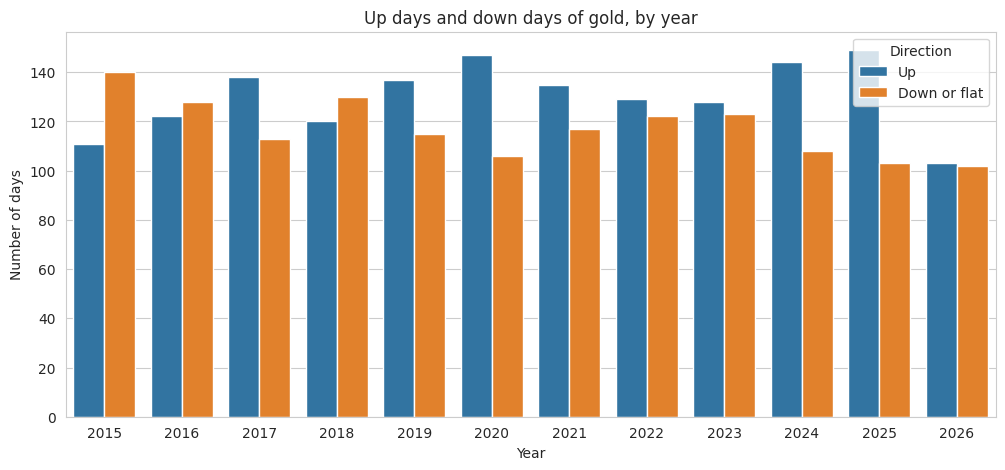

In [170]:
# Remove the first row (it has no return)
days = df.dropna(subset=["Gold_Return"]).copy()

# New column: was the day up, or down/flat?
days["Direction"] = np.where(days["Gold_Return"] > 0, "Up", "Down or flat")

# Count the days of each type in every year
plt.figure(figsize=(12, 5))
sns.countplot(data=days, x="Year", hue="Direction")
plt.title("Up days and down days of gold, by year")
plt.xlabel("Year")
plt.ylabel("Number of days")

plt.show()

### **What the Data Shows:**

- Gold usually rises or falls by around 1% a day.
- About 5.7% of days (168 out of 2,970) had unusually large changes: a drop of more than 2.0% or a rise of more than 2.1%.
- The biggest daily drop was 10.8%, while the biggest daily rise was 6.0%.
- Gold went up on more days than it went down in most years, but the difference is small.  
- Years like 2015, 2016 and 2018 had more down days.

### **What it means**

- A daily change of around 1% is common in this dataset and does not necessarily mean something unusual happened.
- I kept the extreme days because they reflect real price changes and help show the risk of gold.
- Day-to-day direction is close to a coin flip, so it is hard to guess tomorrow’s move.

### **Q6. Is gold a good long-term investment?**

In [171]:
# If you buy on any day and sell after N years, how often do you profit?
rows = []

for years in [1, 3, 5]:
    n = years * 252   # about 252 trading days in one year
    holding_return = (df["Close"].shift(-n) - df["Close"]) / df["Close"] * 100
    valid = holding_return.dropna()

    rows.append([str(years) + " year(s)", len(valid),
                 round((valid > 0).mean() * 100, 1),
                 round((valid >= 100).mean() * 100, 1),
                 round(valid.median(), 1),
                 round(valid.min(), 1),
                 round(valid.max(), 1)])

pd.DataFrame(rows, columns=["Holding period", "Buy days tested", "% profitable","% doubled", "Median (%)", "Worst (%)", "Best (%)"])

,Holding period,Buy days tested,% profitable,% doubled,Median (%),Worst (%),Best (%)
0,1 year(s),2719,75.7,0.0,10.1,-15.6,92.0
1,3 year(s),2215,98.3,13.2,33.5,-5.7,189.2
2,5 year(s),1711,100.0,16.4,62.3,20.6,212.4


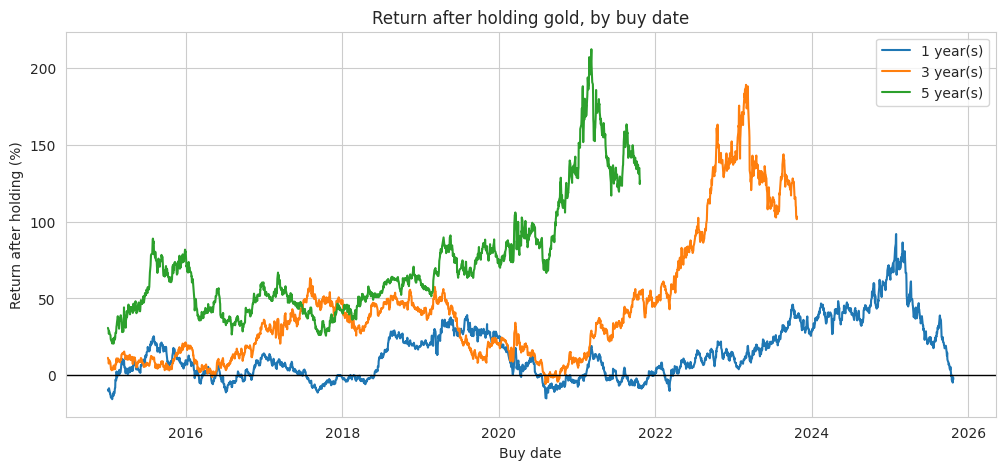

In [172]:
# Plot: return after N years, by the day you bought
plt.figure(figsize=(12, 5))

for years in [1, 3, 5]:
    n = years * 252
    holding_return = (df["Close"].shift(-n) - df["Close"]) / df["Close"] * 100
    plt.plot(df["Date"], holding_return, label=str(years) + " year(s)")

# A line at zero: above it is profit, below it is loss
plt.axhline(0, color="black", linewidth=1)

plt.title("Return after holding gold, by buy date")
plt.xlabel("Buy date")
plt.ylabel("Return after holding (%)")
plt.legend()
plt.show()


### **What the Data Shows:**

- I tested buying gold on different dates and selling it after 1, 3, or 5 years. Each holding period includes only purchase dates with enough future data to calculate the result.  

- Selling after 1 year gave a profit in 75.7% of the cases tested. This means about 76 out of every 100 purchases ended with a selling price higher than the buying price.  
- Selling after 3 years gave a profit in 98.3% of the cases tested. This means about 98 out of every 100 purchases ended with a selling price higher than the buying price.  
- Selling after 5 years gave a profit in every case tested. For every purchase date with 5 years of data available afterward, the price after 5 years was higher than the buying price.  


- The worst 3-year result was a 5.7% loss. For example, an investment of $1,000 would have fallen to about $943 after 3 years.  

- The worst 5-year result was a 20.6% gain. This means even the least profitable 5-year period tested turned $1,000 into about $1,206.

### **What it means**

- **Gold performed better over longer holding periods in this dataset**.
Holding for just 1 year resulted in a loss in about 24% of the cases, while losses were much less common over 3 years, and **none occurred** over the 5-year periods tested.

- These results support gold as a long-term investment during the period studied, but they do not mean that time guarantees a profit. The data covers 2015–2026, a strong period for gold, and future results may differ.

- The lines stop early because we cannot calculate a 5-year result for someone who bought less than 5 years before the data ended.

### **Gold Price in SAR per Gram**
I converted the price to Saudi riyals per gram for the dashboard calculator.

In [173]:
# Convert gold price from USD per ounce to SAR per gram for each karat
OUNCE_IN_GRAMS = 31.1035
USD_TO_SAR = 3.75

df["Gold_24K_SAR"] = df["Close"] / OUNCE_IN_GRAMS * USD_TO_SAR
df["Gold_21K_SAR"] = df["Gold_24K_SAR"] * 21 / 24
df["Gold_18K_SAR"] = df["Gold_24K_SAR"] * 18 / 24

df[["Date", "Gold_24K_SAR", "Gold_21K_SAR", "Gold_18K_SAR"]].tail()

,Date,Gold_24K_SAR,Gold_21K_SAR,Gold_18K_SAR
2966,2026-10-20,499.453449,437.021768,374.590087
2967,2026-10-21,500.345620,437.802418,375.259215
2968,2026-10-22,489.542966,428.350095,367.157224
2969,2026-10-23,483.213292,422.811631,362.409969
2970,2026-10-26,486.890531,426.029215,365.167898


## **9. Final Summary**

**Main Insights**

- Gold rose about 240%, from 1,186 USD in January 2015 to 4,038 USD in October 2026. However, the rise was not steady, and the final price was about 24% below its January 2026 peak.
- Gold rose in 8 of the 12 years studied. The strongest year was 2025 (+62.6%), while 2015 was the weakest complete year (-10.6%).
- Gold and oil prices had a correlation of 0.43, but their daily returns had a correlation of only 0.04. This shows almost no linear relationship between their daily movements.
- Gold reacted differently across the three global events studied. It did not consistently rise after every event.
- Daily gold moves were usually around 1%. About 5.7% of days had unusually large changes, and the largest drop from a previous peak was 24.9%.
- Holding for 1 year made a profit in 75.7% of the periods tested, compared with 98.3% for 3 years and 100% for 5 years.

**What I Learned**

- How to clean and merge datasets, handle missing values, and deal with negative oil prices.
- Why comparing daily returns can give a different picture from comparing prices.
- Unusual values can reflect real events and should not be removed automatically.
- My expectation of a strong inverse relationship between gold and oil was not supported by their daily returns.

**Limitations**

- The study covers 2015–2026, a strong period for gold. Future results may differ.
- Gold futures prices differ from jewelry shop prices. Manufacturing charges and VAT are not included.
- Missing oil prices were filled using the last available price, which may affect daily returns and correlation.
- Only three global events were studied. Price changes around an event do not prove that the event caused them.

**Recommendations for Future Analysis**

- Test a model for predicting gold price movements.